# Phát hiện giao dịch gian lận bằng Autoencoder
## So sánh Autoencoder độc lập và Autoencoder kết hợp XGBoost

**Mục tiêu**
- Xây dựng Autoencoder học cách tái tạo giao dịch bình thường (`Class = 0`).
- Dùng sai số tái tạo (*reconstruction error*) để phát hiện giao dịch bất thường.
- Kết hợp đặc trưng ẩn của Autoencoder và sai số tái tạo với XGBoost để phân loại có giám sát.
- So sánh hai phương pháp trên cùng tập kiểm tra, đặc biệt chú ý đến giao dịch gian lận hiếm.

**Quy ước nhãn:** `Class = 0` là giao dịch bình thường; `Class = 1` là giao dịch gian lận.

> Lưu ý: kết quả số liệu chỉ có ý nghĩa sau khi chạy toàn bộ notebook với đúng file dữ liệu. Không nên ghi trước một kết quả kỳ vọng vào báo cáo.

## 1. Tổng quan hai phương pháp

### Phương pháp A — Autoencoder phát hiện bất thường
Autoencoder chỉ được huấn luyện trên giao dịch bình thường. Mô hình học cách nén rồi tái tạo những mẫu bình thường. Nếu một giao dịch có sai số tái tạo cao hơn ngưỡng đã chọn từ tập validation bình thường, giao dịch đó được gắn cờ là bất thường.

### Phương pháp B — Autoencoder + XGBoost
Dùng Autoencoder đã học từ giao dịch bình thường để tạo:
1. **Latent features:** biểu diễn nén ở lớp giữa của mạng.
2. **Reconstruction error:** mức độ khó tái tạo giao dịch.

Sau đó, XGBoost học từ các đặc trưng này cùng nhãn `Class` của tập huấn luyện để phân loại bình thường/gian lận. Phương pháp này có sử dụng nhãn gian lận trong giai đoạn huấn luyện XGBoost, vì vậy không còn là phát hiện bất thường hoàn toàn không giám sát.

## 2. Cài đặt thư viện

Nếu môi trường chưa có thư viện nào, bỏ dấu `#` ở dòng tương ứng và chạy trong terminal/Jupyter. TensorFlow và XGBoost có thể cần cài đặt riêng tùy môi trường.

In [1]:
# Chạy khi cần cài đặt (bỏ dấu # ở đầu dòng dưới rồi chạy cell):
# %pip install pandas numpy matplotlib seaborn scikit-learn tensorflow xgboost
# pandas/numpy: xử lý dữ liệu | matplotlib/seaborn: vẽ biểu đồ
# scikit-learn: chia tập, chuẩn hóa, đo chỉ số | tensorflow: xây Autoencoder | xgboost: bộ phân loại ở phương pháp B

## 3. Nạp dữ liệu và thư viện

Đổi `DATA_PATH` thành vị trí file `creditcard.csv` trên máy bạn. Nếu file nằm cùng thư mục với notebook, chỉ cần dùng `"creditcard.csv"`.

In [2]:
# ===== Thư viện hệ thống =====
from pathlib import Path   # Path: làm việc với đường dẫn file (chạy được trên cả Windows/Mac/Linux)
import warnings
warnings.filterwarnings("ignore")  # Tắt các cảnh báo (warning) để output gọn hơn

# ===== Thư viện xử lý dữ liệu và vẽ biểu đồ =====
import numpy as np               # Tính toán trên mảng số
import pandas as pd              # Đọc/xử lý bảng dữ liệu (DataFrame)
import matplotlib.pyplot as plt  # Vẽ biểu đồ cơ bản
import seaborn as sns            # Vẽ biểu đồ thống kê đẹp hơn (histogram, heatmap...)

# ===== Thư viện scikit-learn =====
from sklearn.model_selection import train_test_split  # Chia dữ liệu thành tập train/test
from sklearn.preprocessing import StandardScaler       # Chuẩn hóa: (x - trung bình) / độ lệch chuẩn
from sklearn.metrics import (
    classification_report, confusion_matrix,           # Báo cáo phân loại, ma trận nhầm lẫn
    precision_score, recall_score, f1_score,           # Precision, Recall, F1
    average_precision_score, roc_auc_score,            # PR-AUC (Average Precision), ROC-AUC
    precision_recall_curve, roc_curve                  # Dữ liệu để vẽ đường PR / ROC
)

# ===== Thư viện TensorFlow / Keras (để xây Autoencoder) =====
import tensorflow as tf
from tensorflow.keras import Model, layers, callbacks  # Model: đóng gói mạng; layers: các lớp; callbacks: hàm gọi khi train (vd EarlyStopping)

# Cố định seed để kết quả có thể lặp lại giữa các lần chạy
SEED = 42
np.random.seed(SEED)       # Seed cho numpy
tf.random.set_seed(SEED)   # Seed cho TensorFlow (khởi tạo trọng số, shuffle...)

# Sửa đường dẫn này nếu file CSV không nằm cạnh notebook.
DATA_PATH = Path("creditcard.csv")
if not DATA_PATH.exists():  # Nếu không thấy file ở thư mục hiện tại thì thử đường dẫn dự phòng
    # Đường dẫn cũ có trong notebook ban đầu; có thể sửa hoặc bỏ nếu không dùng Windows.
    fallback = Path(r"D:\DataMining26\Autoencoders (Seminar)\Data\ForPractical\creditcard\creditcard.csv")
    if fallback.exists():
        DATA_PATH = fallback
    else:
        # Dừng chương trình và báo lỗi rõ ràng cho người dùng
        raise FileNotFoundError(
            "Không tìm thấy creditcard.csv. Hãy sửa DATA_PATH ở cell này "
            "thành đường dẫn chính xác đến file CSV."
        )

df = pd.read_csv(DATA_PATH)  # Đọc file CSV thành DataFrame
print(f"Kích thước dữ liệu: {df.shape[0]:,} dòng × {df.shape[1]} cột")  # shape = (số dòng, số cột)
display(df.head())           # Hiển thị 5 dòng đầu để xem cấu trúc dữ liệu

Kích thước dữ liệu: 284,807 dòng × 31 cột


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 4. Khám phá dữ liệu (EDA)

Bộ dữ liệu phổ biến này có các đặc trưng `V1`–`V28`, `Time`, `Amount` và nhãn `Class`. Ta bỏ `Time` khỏi hai mô hình trong thí nghiệm này để tập trung vào `V1`–`V28` và `Amount`; đây là lựa chọn thực nghiệm, không phải quy tắc bắt buộc cho mọi bài toán.

In [3]:
print("Thông tin kiểu dữ liệu:")
df.info()  # Liệt kê tên cột, kiểu dữ liệu, số giá trị không rỗng, dung lượng bộ nhớ

print("\nGiá trị thiếu theo cột (chỉ hiện cột có thiếu):")
# df.isna().sum(): đếm số ô trống của từng cột; lọc ra chỉ những cột có > 0 ô trống
display(df.isna().sum()[df.isna().sum() > 0])

# df.duplicated(): đánh dấu dòng trùng hoàn toàn với dòng trước đó; .sum() đếm số dòng trùng
print(f"Số dòng trùng hoàn toàn: {df.duplicated().sum():,}")

print("\nPhân bố nhãn:")
# value_counts(): đếm số giao dịch mỗi nhãn; rename đổi 0/1 thành tên dễ đọc; to_frame đổi sang bảng
display(df["Class"].value_counts().rename(index={0: "Normal (0)", 1: "Fraud (1)"}).to_frame("Số giao dịch"))

print("\nTỷ lệ nhãn (%):")
# normalize=True: trả về tỷ lệ thay vì số đếm; nhân 100 để ra phần trăm; round(4) làm tròn 4 chữ số
display((df["Class"].value_counts(normalize=True) * 100).rename(index={0: "Normal (0)", 1: "Fraud (1)"}).round(4).to_frame("Tỷ lệ (%)"))

Thông tin kiểu dữ liệu:
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 2

Series([], dtype: int64)

Số dòng trùng hoàn toàn: 1,081

Phân bố nhãn:


,Số giao dịch
Class,
Normal (0),284315
Fraud (1),492



Tỷ lệ nhãn (%):


,Tỷ lệ (%)
Class,
Normal (0),99.8273
Fraud (1),0.1727


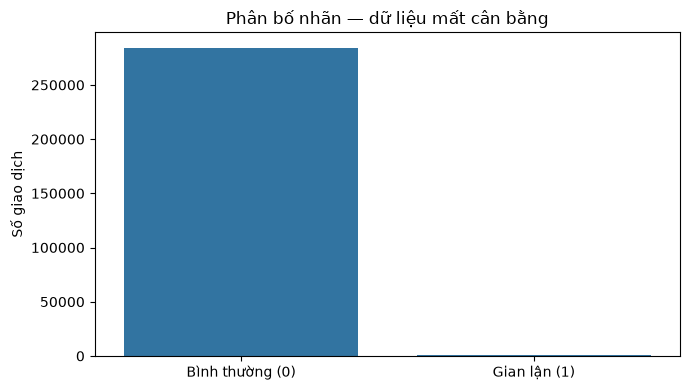

In [4]:
# Đếm số giao dịch theo từng nhãn, sắp theo thứ tự nhãn 0 rồi 1
counts = df["Class"].value_counts().sort_index()

plt.figure(figsize=(7, 4))  # Tạo khung hình rộng 7, cao 4 (inch)
# Vẽ biểu đồ cột; counts.get(k, 0) trả về 0 nếu nhãn k không tồn tại (tránh lỗi)
sns.barplot(x=["Bình thường (0)", "Gian lận (1)"], y=[counts.get(0, 0), counts.get(1, 0)])
plt.title("Phân bố nhãn — dữ liệu mất cân bằng")
plt.ylabel("Số giao dịch")
plt.xlabel("")        # Bỏ nhãn trục x (đã có tên cột)
plt.tight_layout()    # Tự căn lề cho không bị cắt chữ
plt.show()

### Nhận xét EDA
- Nếu số giao dịch `Class = 1` nhỏ hơn rất nhiều so với `Class = 0`, dữ liệu bị **mất cân bằng lớp**.
- Accuracy có thể gây hiểu nhầm: mô hình đoán tất cả là bình thường vẫn có thể đạt accuracy rất cao.
- Vì vậy, cần theo dõi **Precision, Recall, F1-score, PR-AUC** và confusion matrix. Trong phát hiện gian lận, Recall thể hiện tỷ lệ giao dịch gian lận được tìm ra; Precision thể hiện tỷ lệ cảnh báo gian lận thực sự là gian lận.

## 5. Chuẩn bị dữ liệu và chia tập

Ta chia train/test theo tỷ lệ 80/20 và dùng `stratify=y` để giữ tỷ lệ nhãn gần giống nhau. Tập test chỉ dùng ở bước đánh giá cuối.

**Tránh rò rỉ dữ liệu:** scaler chỉ được `fit` trên giao dịch bình thường thuộc tập train. Autoencoder cũng chỉ được học từ giao dịch bình thường thuộc train. Không dùng nhãn test để chọn ngưỡng.

In [5]:
# ----- Kiểm tra dữ liệu đầu vào hợp lệ trước khi xử lý -----
required = {"Class"}
if not required.issubset(df.columns):  # Có cột Class không?
    raise ValueError("Dữ liệu cần có cột Class.")
if df["Class"].isna().any():           # Cột Class có ô trống không?
    raise ValueError("Cột Class có giá trị thiếu; hãy xử lý trước khi chạy.")
if not set(df["Class"].unique()).issubset({0, 1}):  # Nhãn chỉ được là 0 hoặc 1
    raise ValueError("Notebook này yêu cầu Class được mã hóa 0=bình thường, 1=gian lận.")

# ----- Tách đặc trưng (X) và nhãn (y) -----
# Chọn đặc trưng theo thiết kế thí nghiệm; loại bỏ nhãn và cột Time.
feature_cols = [c for c in df.columns if c not in ["Time", "Class"]]  # Còn lại V1–V28 và Amount
X_raw = df[feature_cols].astype("float32").to_numpy()  # Đặc trưng -> mảng numpy float32 (nhẹ bộ nhớ, hợp với TensorFlow)
y = df["Class"].astype("int32").to_numpy()             # Nhãn -> mảng numpy số nguyên

# ----- Chia train/test = 80/20 -----
# stratify=y: giữ nguyên tỷ lệ gian lận ở cả train và test (rất quan trọng vì gian lận cực hiếm)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.20, stratify=y, random_state=SEED
)

# Autoencoder học trên phần giao dịch bình thường của train.
X_train_normal_raw = X_train_raw[y_train == 0]  # Lọc chỉ giữ các dòng có nhãn 0

# ----- Chuẩn hóa dữ liệu -----
scaler = StandardScaler()
scaler.fit(X_train_normal_raw)  # Chỉ "học" trung bình/độ lệch chuẩn từ giao dịch bình thường của train (tránh rò rỉ dữ liệu)

# Áp dụng cùng một scaler cho train và test để hai tập cùng thang đo
X_train_scaled = scaler.transform(X_train_raw).astype("float32")
X_test_scaled = scaler.transform(X_test_raw).astype("float32")
X_train_normal = X_train_scaled[y_train == 0]  # Tập dùng để huấn luyện Autoencoder (chỉ giao dịch bình thường)

print("Số đặc trưng:", len(feature_cols))
print("Train:", X_train_scaled.shape, "| Test:", X_test_scaled.shape)
print("Giao dịch bình thường dùng train Autoencoder:", X_train_normal.shape[0])
print("Giao dịch train gian lận (chỉ dùng để huấn luyện XGBoost):", int((y_train == 1).sum()))

Số đặc trưng: 29
Train: (227845, 29) | Test: (56962, 29)
Giao dịch bình thường dùng train Autoencoder: 227451
Giao dịch train gian lận (chỉ dùng để huấn luyện XGBoost): 394


## 6. Hàm xây dựng Autoencoder

Kiến trúc đơn giản: đầu vào → lớp nén (*encoder*) → lớp tái tạo (*decoder*).

Vì đầu vào đã chuẩn hóa bằng `StandardScaler` nên giá trị có thể âm hoặc lớn hơn 1. Do đó, lớp đầu ra dùng **linear activation** (không dùng sigmoid), để tránh ép giá trị tái tạo vào khoảng 0–1.

In [6]:
def build_autoencoder(input_dim, encoding_dim=14, learning_rate=1e-3):
    """Xây Autoencoder đơn giản: input -> latent (nén) -> output (tái tạo).
    Trả về 2 mô hình dùng chung trọng số: autoencoder (đầy đủ) và encoder (chỉ nửa nén)."""

    # BƯỚC 1 - Lớp đầu vào: nhận 1 giao dịch gồm input_dim đặc trưng (ở đây là 29: V1–V28 + Amount)
    inputs = layers.Input(shape=(input_dim,), name="input_features")

    # BƯỚC 2 - ENCODER (nén): Dense nén 29 chiều xuống encoding_dim chiều (14).
    # Đây là "nút thắt cổ chai" (bottleneck): ép mạng chỉ giữ thông tin quan trọng nhất của giao dịch bình thường.
    # activation="relu": giữ giá trị dương, cắt giá trị âm về 0 -> thêm tính phi tuyến
    latent = layers.Dense(encoding_dim, activation="relu", name="latent_space")(inputs)

    # BƯỚC 3 - DECODER (tái tạo): Dense phóng từ 14 chiều trở lại 29 chiều, cố gắng khôi phục giao dịch gốc.
    # Linear output phù hợp với dữ liệu đã StandardScaler (giá trị có thể âm hoặc >1, không bị ép vào 0–1).
    outputs = layers.Dense(input_dim, activation="linear", name="reconstruction")(latent)

    # BƯỚC 4 - Đóng gói thành mô hình
    autoencoder = Model(inputs, outputs, name="autoencoder")  # Toàn bộ: input -> latent -> output (dùng để train)
    encoder = Model(inputs, latent, name="encoder")           # Chỉ nửa đầu: input -> latent (dùng lấy đặc trưng ẩn cho XGBoost)

    # BƯỚC 5 - Cấu hình học
    autoencoder.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),  # Adam: thuật toán cập nhật trọng số; learning_rate = bước học
        loss="mse"  # Mean Squared Error: trung bình bình phương chênh lệch giữa đầu vào và đầu ra tái tạo
    )
    return autoencoder, encoder

input_dim = X_train_normal.shape[1]                    # Số đặc trưng đầu vào (số cột của dữ liệu)
encoding_dim = min(14, max(2, input_dim - 1))          # Kích thước lớp nén: 14, nhưng luôn nằm trong khoảng [2, input_dim-1] để thật sự "nén"
autoencoder, encoder = build_autoencoder(input_dim, encoding_dim)

autoencoder.summary()  # In cấu trúc mạng: các lớp, kích thước đầu ra, số tham số

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_features (InputLayer)     │ (None, 29)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_space (Dense)            │ (None, 14)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstruction (Dense)          │ (None, 29)             │           435 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 855 (3.34 KB)

 Trainable params: 855 (3.34 KB)

 Non-trainable params: 0 (0.00 B)

## 7. Phương pháp A — Autoencoder độc lập

### 7.1 Huấn luyện chỉ bằng giao dịch bình thường
`validation_split` lấy một phần dữ liệu bình thường dùng trong train để theo dõi quá trình học. Early stopping dừng khi validation loss không còn cải thiện đáng kể.

Epoch 1/50
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.6956 - val_loss: 0.5089
Epoch 2/50
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.4981 - val_loss: 0.4586
Epoch 3/50
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.4730 - val_loss: 0.4499
Epoch 4/50
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4679 - val_loss: 0.4470
Epoch 5/50
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - loss: 0.4656 - val_loss: 0.4453
Epoch 6/50
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4641 - val_loss: 0.4441
Epoch 7/50
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.4630 - val_loss: 0.4432
Epoch 8/50
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.4622 - val_loss: 0.4426
Epoch 9/50
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.4615 - val_loss: 0.4421
Epoch 10/50
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.4610 - val_loss: 0.4417
Epoch 11/50
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.4605 - val_loss: 0.4414
Epoch 12/50
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step

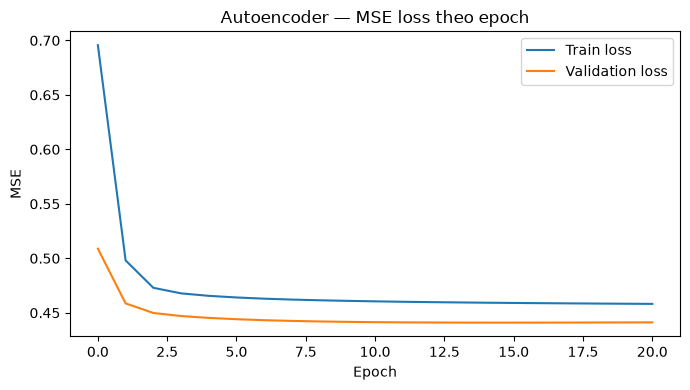

In [7]:
# Early stopping: tự dừng train khi mô hình không còn cải thiện -> tránh học quá mức (overfitting) và tiết kiệm thời gian
early_stop = callbacks.EarlyStopping(
    monitor="val_loss",          # Theo dõi loss trên tập validation
    patience=5,                  # Cho phép 5 epoch liên tiếp không cải thiện trước khi dừng
    restore_best_weights=True    # Khi dừng, khôi phục trọng số của epoch tốt nhất
)

# Huấn luyện Autoencoder: input = target = chính giao dịch bình thường
# (mạng học tái tạo lại đầu vào, nên "nhãn" chính là dữ liệu vào)
history = autoencoder.fit(
    X_train_normal, X_train_normal,
    validation_split=0.10,   # Lấy 10% cuối dữ liệu làm validation để theo dõi val_loss
    epochs=50,               # Tối đa 50 lượt duyệt toàn bộ dữ liệu
    batch_size=256,          # Mỗi lần cập nhật trọng số dùng 256 mẫu
    shuffle=True,            # Xáo trộn dữ liệu mỗi epoch
    callbacks=[early_stop],
    verbose=1                # In tiến trình huấn luyện
)

# Vẽ đường cong loss: nếu train loss giảm mà val loss tăng => dấu hiệu overfitting
plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="Train loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("Autoencoder — MSE loss theo epoch")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.legend()
plt.tight_layout()
plt.show()

### 7.2 Chọn ngưỡng từ validation bình thường

Dùng một tập validation gồm các giao dịch bình thường chưa được dùng để cập nhật trọng số, lấy phân vị 99% của reconstruction error làm ngưỡng ban đầu. Giao dịch có lỗi tái tạo lớn hơn ngưỡng sẽ bị gắn cờ.

Đây là một **quy tắc vận hành** có thể điều chỉnh, không phải ngưỡng tối ưu phổ quát. Ngưỡng 99% thường tạo khoảng 1% cảnh báo trên dữ liệu validation bình thường, nhưng tỷ lệ trên dữ liệu mới có thể khác.

In [8]:
# ----- Tách validation bình thường riêng để chọn ngưỡng -----
# Tạo validation bình thường riêng từ phần train bình thường.
# Dùng split riêng để ngưỡng không dựa trên chính các mẫu đã dùng cập nhật trọng số.
# X_ae_fit (90%): để huấn luyện | X_ae_val (10%): để theo dõi loss và chọn ngưỡng
X_ae_fit, X_ae_val = train_test_split(
    X_train_normal, test_size=0.10, random_state=SEED
)

# ----- Huấn luyện lại Autoencoder từ đầu -----
# Huấn luyện lại mô hình từ đầu trên phần fit; validation_data là normal holdout.
autoencoder, encoder = build_autoencoder(input_dim, encoding_dim)  # Tạo mạng mới (trọng số khởi tạo lại)
history = autoencoder.fit(
    X_ae_fit, X_ae_fit,                        # Học tái tạo giao dịch bình thường
    validation_data=(X_ae_val, X_ae_val),      # Validation cố định (khác với validation_split ở cell trước)
    epochs=50,
    batch_size=256,
    shuffle=True,
    callbacks=[callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)],
    verbose=1
)

# ----- Hàm tính sai số tái tạo (reconstruction error) -----
def reconstruction_error(model, data, batch_size=1024):
    """Trả về MSE của từng giao dịch: càng lớn nghĩa là mạng càng khó tái tạo => càng 'lạ'."""
    reconstructed = model.predict(data, batch_size=batch_size, verbose=0)  # Giao dịch sau khi qua encoder + decoder
    # (gốc - tái tạo)^2 rồi lấy trung bình trên các đặc trưng (axis=1) => 1 con số cho mỗi giao dịch
    return np.mean(np.square(data - reconstructed), axis=1)

# ----- Chọn ngưỡng phát hiện bất thường -----
val_errors = reconstruction_error(autoencoder, X_ae_val)        # Sai số của các giao dịch bình thường ở validation
THRESHOLD_AE = float(np.quantile(val_errors, 0.99))             # Ngưỡng = phân vị 99%: ~99% giao dịch bình thường nằm dưới ngưỡng này

# ----- Dự đoán trên tập test -----
test_errors_ae = reconstruction_error(autoencoder, X_test_scaled)  # Sai số tái tạo của mọi giao dịch test
y_pred_ae = (test_errors_ae > THRESHOLD_AE).astype(int)            # Sai số > ngưỡng => dự đoán 1 (gian lận), ngược lại 0

print(f"Ngưỡng reconstruction error (phân vị 99% normal validation): {THRESHOLD_AE:.6f}")
print(f"Trung vị lỗi validation normal: {np.median(val_errors):.6f}")
print(f"Phân vị 99% lỗi validation normal: {np.quantile(val_errors, 0.99):.6f}")

Epoch 1/50
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.7304 - val_loss: 0.5433
Epoch 2/50
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.5124 - val_loss: 0.4768
Epoch 3/50
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.4755 - val_loss: 0.4623
Epoch 4/50
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.4676 - val_loss: 0.4588
Epoch 5/50
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.4648 - val_loss: 0.4572
Epoch 6/50
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.4632 - val_loss: 0.4563
Epoch 7/50
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.4621 - val_loss: 0.4558
Epoch 8/50
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.4613 - val_loss: 0.4554
Epoch 9/50
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4606 - val_loss: 0.4552
Epoch 10/50
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.4600 - val_loss: 0.4550
Epoch 11/50
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4595 - val_loss: 0.4549
Epoch 12/50
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step

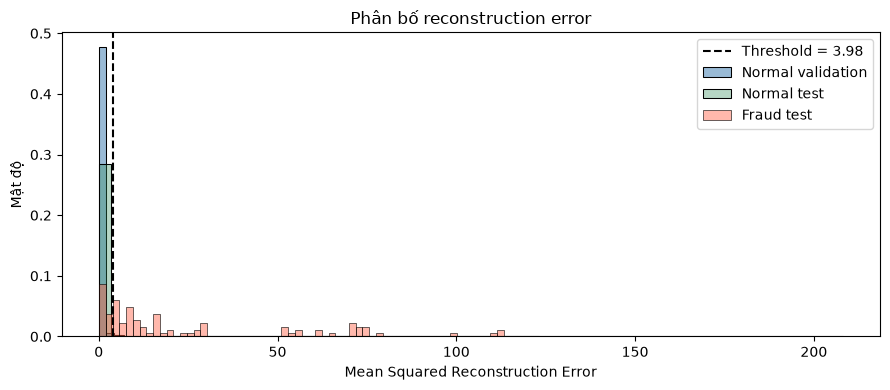

In [9]:
plt.figure(figsize=(9, 4))
# Histogram sai số tái tạo của 3 nhóm; stat="density" chuẩn hóa để so sánh được dù số lượng mẫu khác xa nhau
sns.histplot(val_errors, bins=60, stat="density", color="steelblue", alpha=0.55, label="Normal validation")
sns.histplot(test_errors_ae[y_test == 0], bins=60, stat="density", color="seagreen", alpha=0.35, label="Normal test")
sns.histplot(test_errors_ae[y_test == 1], bins=60, stat="density", color="tomato", alpha=0.45, label="Fraud test")
# Đường đứt nét đen = ngưỡng; bên phải đường này bị gắn cờ là bất thường
plt.axvline(THRESHOLD_AE, color="black", linestyle="--", label=f"Threshold = {THRESHOLD_AE:.4g}")
plt.title("Phân bố reconstruction error")
plt.xlabel("Mean Squared Reconstruction Error")
plt.ylabel("Mật độ")
plt.legend()
plt.tight_layout()
plt.show()

### 7.3 Đánh giá phương pháp A

Ngưỡng được chọn từ validation bình thường, không dùng nhãn test. Các chỉ số test bên dưới phản ánh hiệu quả của quy tắc ngưỡng này; nếu Recall thấp, có thể cần điều chỉnh ngưỡng bằng validation có nhãn hoặc theo chi phí nghiệp vụ — nhưng khi đó cần nói rõ đã sử dụng nhãn.

===== A — Autoencoder threshold =====
              precision    recall  f1-score   support

  Normal (0)     0.9996    0.9895    0.9945     56864
   Fraud (1)     0.1104    0.7551    0.1927        98

    accuracy                         0.9891     56962
   macro avg     0.5550    0.8723    0.5936     56962
weighted avg     0.9980    0.9891    0.9931     56962

Confusion matrix [ [TN, FP], [FN, TP] ]:
[[56268   596]
 [   24    74]]


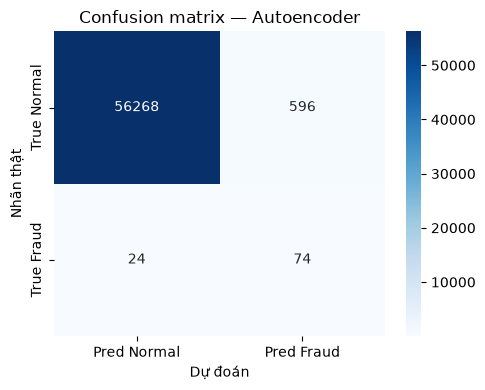

In [10]:
def evaluate_predictions(y_true, y_pred, y_score=None, model_name="Mô hình"):
    """In báo cáo đánh giá và trả về (dict các chỉ số, confusion matrix).
    y_true: nhãn thật | y_pred: nhãn dự đoán 0/1 | y_score: điểm liên tục (dùng tính AUC)"""
    print(f"===== {model_name} =====")
    # Báo cáo Precision/Recall/F1 cho từng lớp; zero_division=0 tránh lỗi khi không dự đoán được mẫu nào của lớp
    print(classification_report(
        y_true, y_pred, labels=[0, 1],
        target_names=["Normal (0)", "Fraud (1)"],
        digits=4, zero_division=0
    ))
    # Ma trận nhầm lẫn: hàng = nhãn thật, cột = dự đoán
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    print("Confusion matrix [ [TN, FP], [FN, TP] ]:")
    print(cm)
    result = {
        "Mô hình": model_name,
        "Precision (Fraud)": precision_score(y_true, y_pred, zero_division=0),  # Trong số cảnh báo gian lận, bao nhiêu % đúng
        "Recall (Fraud)": recall_score(y_true, y_pred, zero_division=0),        # Trong số gian lận thật, bắt được bao nhiêu %
        "F1 (Fraud)": f1_score(y_true, y_pred, zero_division=0),                # Trung bình điều hòa của Precision và Recall
        # PR-AUC và ROC-AUC dùng điểm liên tục (y_score), đo chất lượng xếp hạng bất kể ngưỡng
        "PR-AUC / Average Precision": average_precision_score(y_true, y_score) if y_score is not None else np.nan,
        "ROC-AUC": roc_auc_score(y_true, y_score) if y_score is not None else np.nan,
    }
    return result, cm

# Đánh giá Phương pháp A: điểm bất thường chính là reconstruction error
result_ae, cm_ae = evaluate_predictions(
    y_test, y_pred_ae, y_score=test_errors_ae,
    model_name="A — Autoencoder threshold"
)

# Vẽ confusion matrix dạng heatmap; annot=True ghi số vào ô, fmt="d" hiển thị số nguyên
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm_ae, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Pred Normal", "Pred Fraud"],
            yticklabels=["True Normal", "True Fraud"], ax=ax)
ax.set_title("Confusion matrix — Autoencoder")
ax.set_xlabel("Dự đoán")
ax.set_ylabel("Nhãn thật")
plt.tight_layout()
plt.show()

## 8. Phương pháp B — Autoencoder + XGBoost

### Ý tưởng
Autoencoder cung cấp biểu diễn nén và lỗi tái tạo; XGBoost học cách kết hợp các đặc trưng này để dự đoán `Class`. Khác với phương pháp A, XGBoost là bộ phân loại có giám sát và cần các nhãn `Class` trong tập train.

**Lưu ý quan trọng:** Autoencoder vẫn chỉ train trên giao dịch bình thường. XGBoost được huấn luyện bằng đặc trưng của cả giao dịch bình thường và gian lận trong tập train. Tập test vẫn giữ nguyên và chỉ dùng đánh giá.

In [11]:
# Tạo đặc trưng mới cho XGBoost từ Autoencoder ĐÃ HUẤN LUYỆN (không train lại).
# Tạo latent features và reconstruction error cho train/test bằng Autoencoder đã train.

# (1) Latent features: cho giao dịch đi qua encoder, lấy vector 14 chiều ở lớp nén (biểu diễn "cốt lõi" của giao dịch)
latent_train = encoder.predict(X_train_scaled, batch_size=1024, verbose=0)
latent_test = encoder.predict(X_test_scaled, batch_size=1024, verbose=0)

# (2) Reconstruction error: mức độ Autoencoder khó tái tạo giao dịch (giao dịch lạ thường có sai số cao)
# Lưu ý: tính trên TOÀN BỘ train (cả bình thường lẫn gian lận) vì XGBoost cần cả hai loại
error_train = reconstruction_error(autoencoder, X_train_scaled)
error_test = reconstruction_error(autoencoder, X_test_scaled)

# (3) Ghép lại: mỗi giao dịch = 14 latent + 1 reconstruction error = 15 đặc trưng
# column_stack ghép các cột cạnh nhau (error là mảng 1 chiều nên được coi là 1 cột)
X_train_hybrid = np.column_stack([latent_train, error_train])
X_test_hybrid = np.column_stack([latent_test, error_test])

print("Số đặc trưng latent:", latent_train.shape[1])
print("Số đặc trưng hybrid:", X_train_hybrid.shape[1], "(latent + reconstruction error)")

Số đặc trưng latent: 14
Số đặc trưng hybrid: 15 (latent + reconstruction error)


### 8.1 Huấn luyện XGBoost có xử lý mất cân bằng

`scale_pos_weight = số mẫu bình thường / số mẫu gian lận` tăng trọng số cho lớp gian lận trong hàm mất mát. Đây là điểm khởi đầu phổ biến, không bảo đảm tối ưu trong mọi trường hợp.

Chọn ngưỡng xác suất bằng **tập validation lấy từ train**, tối đa hóa F1-score. Không chọn ngưỡng trên tập test, vì như vậy sẽ làm kết quả test lạc quan hơn thực tế.

In [12]:
from xgboost import XGBClassifier

# ----- Chia validation từ train để chọn ngưỡng (không đụng tới test) -----
# Chia validation từ tập train cho việc chọn ngưỡng XGBoost.
# stratify=y_train: giữ tỷ lệ gian lận ở cả hai phần
X_hybrid_fit, X_hybrid_val, y_hybrid_fit, y_hybrid_val = train_test_split(
    X_train_hybrid, y_train, test_size=0.20,
    stratify=y_train, random_state=SEED
)

# ----- Xử lý mất cân bằng lớp -----
n_normal = int((y_hybrid_fit == 0).sum())  # Số giao dịch bình thường trong phần fit
n_fraud = int((y_hybrid_fit == 1).sum())   # Số giao dịch gian lận trong phần fit
scale_pos_weight = n_normal / max(n_fraud, 1)  # Tỷ lệ bình thường/gian lận; max(...,1) tránh chia cho 0

# ----- Cấu hình XGBoost -----
xgb_model = XGBClassifier(
    n_estimators=400,         # Số cây quyết định
    max_depth=5,              # Độ sâu tối đa mỗi cây (nhỏ hơn => ít overfitting)
    learning_rate=0.05,       # Mức đóng góp của mỗi cây mới
    subsample=0.9,            # Mỗi cây dùng ngẫu nhiên 90% số mẫu
    colsample_bytree=0.9,     # Mỗi cây dùng ngẫu nhiên 90% số đặc trưng
    objective="binary:logistic",  # Phân loại nhị phân, đầu ra là xác suất gian lận
    eval_metric="aucpr",      # Thang đo nội bộ: diện tích dưới đường Precision–Recall (hợp với dữ liệu mất cân bằng)
    scale_pos_weight=scale_pos_weight,  # Tăng trọng số cho lớp gian lận
    random_state=SEED,
    n_jobs=-1                 # Dùng tất cả nhân CPU
)

xgb_model.fit(X_hybrid_fit, y_hybrid_fit, verbose=False)  # Huấn luyện có giám sát bằng nhãn Class
val_scores_xgb = xgb_model.predict_proba(X_hybrid_val)[:, 1]  # Xác suất gian lận (cột 1) trên validation

# ----- Chọn ngưỡng xác suất tối đa hóa F1 trên validation -----
# precision_recall_curve thử nhiều ngưỡng và trả về Precision/Recall tương ứng
precision_v, recall_v, thresholds_v = precision_recall_curve(y_hybrid_val, val_scores_xgb)
# precision/recall có một phần tử nhiều hơn thresholds; F1 tương ứng với thresholds[:-1].
# F1 = 2PR / (P+R); cộng 1e-12 để tránh chia cho 0
f1_v = 2 * precision_v[:-1] * recall_v[:-1] / (
    precision_v[:-1] + recall_v[:-1] + 1e-12
)
best_idx = int(np.argmax(f1_v))              # Vị trí ngưỡng cho F1 cao nhất
THRESHOLD_XGB = float(thresholds_v[best_idx])  # Ngưỡng xác suất được chọn

print(f"scale_pos_weight = {scale_pos_weight:.2f}")
print(f"Ngưỡng xác suất XGBoost chọn từ validation: {THRESHOLD_XGB:.6f}")
print(f"F1 tốt nhất trên validation: {f1_v[best_idx]:.4f}")

scale_pos_weight = 577.65
Ngưỡng xác suất XGBoost chọn từ validation: 0.989835
F1 tốt nhất trên validation: 0.7770


===== B — Autoencoder + XGBoost =====
              precision    recall  f1-score   support

  Normal (0)     0.9995    0.9998    0.9997     56864
   Fraud (1)     0.8659    0.7245    0.7889        98

    accuracy                         0.9993     56962
   macro avg     0.9327    0.8621    0.8943     56962
weighted avg     0.9993    0.9993    0.9993     56962

Confusion matrix [ [TN, FP], [FN, TP] ]:
[[56853    11]
 [   27    71]]


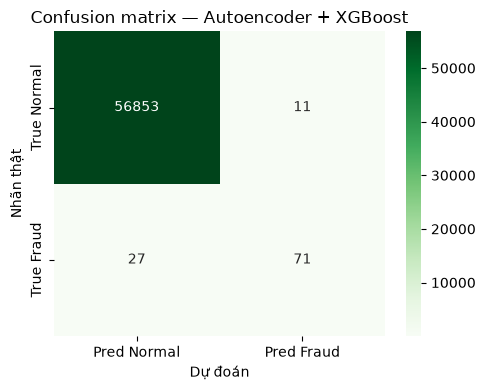

In [13]:
# Dự đoán trên tập test bằng mô hình và ngưỡng đã chọn từ validation (không điều chỉnh theo test)
test_scores_xgb = xgb_model.predict_proba(X_test_hybrid)[:, 1]      # Xác suất gian lận của từng giao dịch test
y_pred_xgb = (test_scores_xgb >= THRESHOLD_XGB).astype(int)         # Xác suất >= ngưỡng => dự đoán gian lận (1)

# Đánh giá bằng cùng hàm với Phương pháp A để so sánh công bằng
result_xgb, cm_xgb = evaluate_predictions(
    y_test, y_pred_xgb, y_score=test_scores_xgb,
    model_name="B — Autoencoder + XGBoost"
)

# Vẽ confusion matrix (màu xanh lá để phân biệt với phương pháp A)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm_xgb, annot=True, fmt="d", cmap="Greens",
            xticklabels=["Pred Normal", "Pred Fraud"],
            yticklabels=["True Normal", "True Fraud"], ax=ax)
ax.set_title("Confusion matrix — Autoencoder + XGBoost")
ax.set_xlabel("Dự đoán")
ax.set_ylabel("Nhãn thật")
plt.tight_layout()
plt.show()

## 9. Sơ đồ kiến trúc hai phương pháp

Các sơ đồ được vẽ bằng Matplotlib ngay trong notebook, không cần Graphviz. Có thể lưu hình để đưa vào slide seminar.

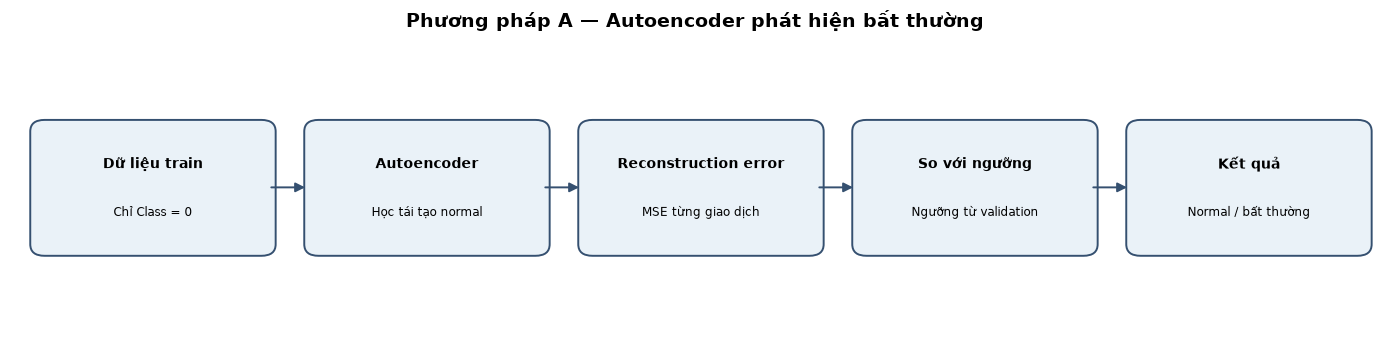

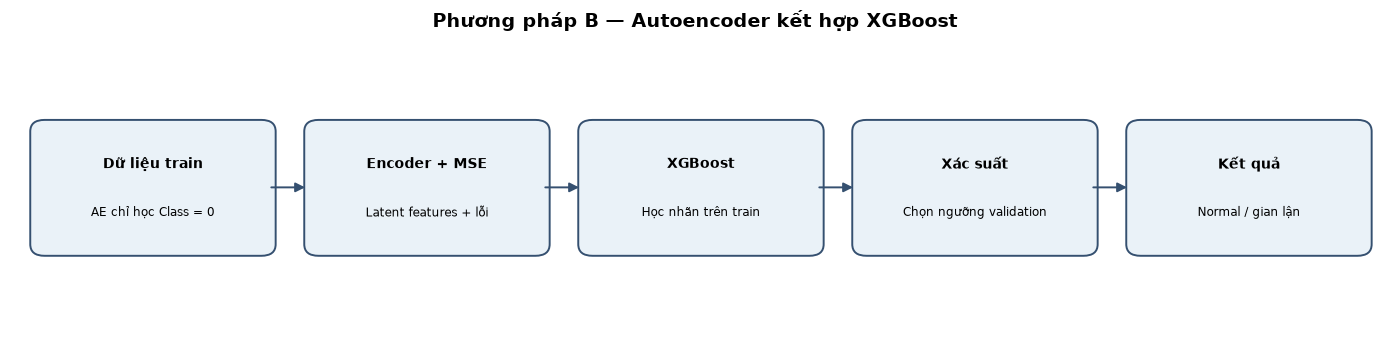

In [14]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch  # Hộp bo góc và mũi tên để vẽ sơ đồ

def draw_flowchart(title, boxes, filename=None):
    """Vẽ sơ đồ luồng ngang. boxes = danh sách (tiêu đề, mô tả); filename: nếu có thì lưu ảnh PNG."""
    fig, ax = plt.subplots(figsize=(14, 3.5))
    ax.set_xlim(0, len(boxes) * 2.3)  # Chiều rộng khung vẽ tỷ lệ với số hộp
    ax.set_ylim(0, 3)
    ax.axis("off")                    # Ẩn trục tọa độ
    positions = []
    for i, (heading, detail) in enumerate(boxes):
        x = 0.25 + i * 2.3            # Tọa độ x của hộp thứ i (cách nhau 2.3 đơn vị)
        # Hộp bo góc màu xanh nhạt
        patch = FancyBboxPatch(
            (x, 0.85), 1.9, 1.25,
            boxstyle="round,pad=0.08,rounding_size=0.12",
            linewidth=1.4, edgecolor="#355070", facecolor="#eaf2f8"
        )
        ax.add_patch(patch)
        # Chữ tiêu đề (đậm) ở nửa trên hộp
        ax.text(x + 0.95, 1.72, heading, ha="center", va="center",
                fontsize=10, fontweight="bold", wrap=True)
        # Chữ mô tả ở nửa dưới hộp
        ax.text(x + 0.95, 1.22, detail, ha="center", va="center",
                fontsize=8.5, wrap=True)
        positions.append(x)
        if i < len(boxes) - 1:  # Vẽ mũi tên nối sang hộp kế tiếp (trừ hộp cuối)
            arrow = FancyArrowPatch(
                (x + 1.92, 1.48), (x + 2.25, 1.48),
                arrowstyle="-|>", mutation_scale=14, linewidth=1.4, color="#355070"
            )
            ax.add_patch(arrow)
    ax.set_title(title, fontsize=14, fontweight="bold", pad=10)
    plt.tight_layout()
    if filename:
        fig.savefig(filename, dpi=200, bbox_inches="tight")  # Lưu ảnh độ phân giải cao để chèn slide
    plt.show()

# Sơ đồ Phương pháp A: Autoencoder + ngưỡng
draw_flowchart(
    "Phương pháp A — Autoencoder phát hiện bất thường",
    [
        ("Dữ liệu train", "Chỉ Class = 0"),
        ("Autoencoder", "Học tái tạo normal"),
        ("Reconstruction error", "MSE từng giao dịch"),
        ("So với ngưỡng", "Ngưỡng từ validation"),
        ("Kết quả", "Normal / bất thường"),
    ],
    "so_do_autoencoder.png"
)

# Sơ đồ Phương pháp B: Autoencoder + XGBoost
draw_flowchart(
    "Phương pháp B — Autoencoder kết hợp XGBoost",
    [
        ("Dữ liệu train", "AE chỉ học Class = 0"),
        ("Encoder + MSE", "Latent features + lỗi"),
        ("XGBoost", "Học nhãn trên train"),
        ("Xác suất", "Chọn ngưỡng validation"),
        ("Kết quả", "Normal / gian lận"),
    ],
    "so_do_autoencoder_xgboost.png"
)

## 10. So sánh kết quả thực nghiệm

Hai mô hình được đánh giá trên cùng tập test. Với Autoencoder, `test_errors_ae` là điểm bất thường; với mô hình kết hợp, `test_scores_xgb` là xác suất gian lận do XGBoost dự đoán.

PR-AUC / Average Precision phù hợp để xem xét chất lượng xếp hạng trong dữ liệu mất cân bằng. Không nên chỉ nhìn accuracy.

,Precision (Fraud),Recall (Fraud),F1 (Fraud),PR-AUC / Average Precision,ROC-AUC
Mô hình,,,,,
A — Autoencoder threshold,0.1104,0.7551,0.1927,0.2636,0.9595
B — Autoencoder + XGBoost,0.8659,0.7245,0.7889,0.8151,0.9718


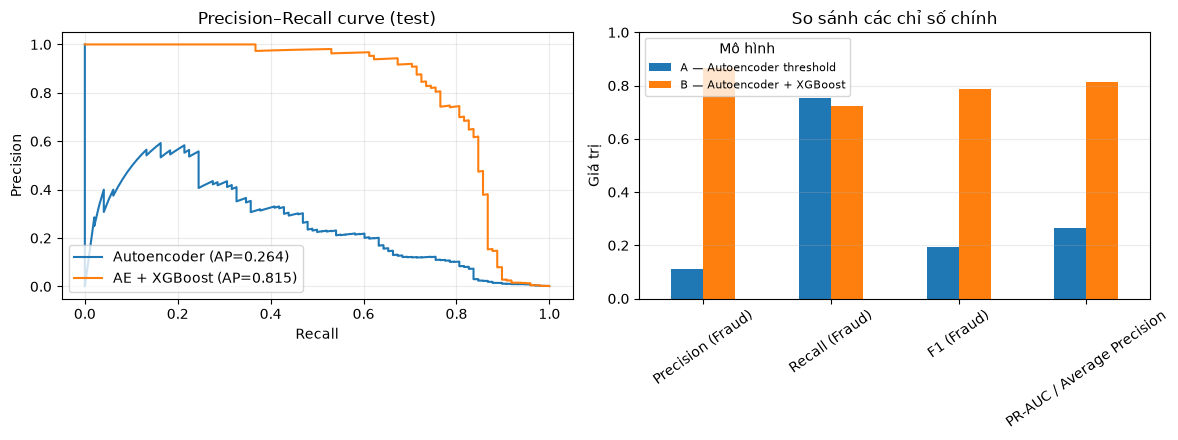

In [15]:
# Gộp kết quả hai phương pháp thành một bảng, mỗi dòng là một mô hình
comparison = pd.DataFrame([result_ae, result_xgb]).set_index("Mô hình")
display(comparison.round(4))

# Tạo khung hình 1 hàng 2 cột: trái = đường PR, phải = biểu đồ cột các chỉ số
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# ----- Biểu đồ trái: Precision–Recall curves trên tập test -----
p_ae, r_ae, _ = precision_recall_curve(y_test, test_errors_ae)     # Đường PR của Autoencoder (điểm = reconstruction error)
p_xgb, r_xgb, _ = precision_recall_curve(y_test, test_scores_xgb)  # Đường PR của AE + XGBoost (điểm = xác suất)
ap_ae = average_precision_score(y_test, test_errors_ae)            # Diện tích dưới đường PR (càng cao càng tốt)
ap_xgb = average_precision_score(y_test, test_scores_xgb)

axes[0].plot(r_ae, p_ae, label=f"Autoencoder (AP={ap_ae:.3f})")
axes[0].plot(r_xgb, p_xgb, label=f"AE + XGBoost (AP={ap_xgb:.3f})")
axes[0].set_title("Precision–Recall curve (test)")
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].legend()
axes[0].grid(alpha=0.25)

# ----- Biểu đồ phải: so sánh các chỉ số chính dạng cột -----
metric_names = ["Precision (Fraud)", "Recall (Fraud)", "F1 (Fraud)", "PR-AUC / Average Precision"]
# .T (transpose): chỉ số nằm trên trục x, mỗi mô hình là một nhóm cột
comparison[metric_names].T.plot(kind="bar", ax=axes[1])
axes[1].set_title("So sánh các chỉ số chính")
axes[1].set_ylabel("Giá trị")
axes[1].set_ylim(0, 1)                    # Các chỉ số đều nằm trong [0, 1]
axes[1].tick_params(axis="x", rotation=35)  # Nghiêng nhãn trục x cho dễ đọc
axes[1].legend(title="Mô hình", fontsize=8)
axes[1].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig("so_sanh_hai_phuong_phap.png", dpi=200, bbox_inches="tight")  # Lưu hình để đưa vào slide
plt.show()

## 11. Kết luận và thảo luận seminar

### Cách diễn giải kết quả
Sau khi chạy notebook, dựa vào bảng so sánh để hoàn thiện các ý sau:

- **Autoencoder độc lập:** không cần nhãn gian lận khi huấn luyện; phù hợp khi chỉ có dữ liệu bình thường hoặc cần phát hiện các mẫu lệch khỏi hành vi bình thường. Kết quả phụ thuộc mạnh vào kiến trúc, cách chuẩn hóa và ngưỡng.
- **Autoencoder + XGBoost:** có thể tận dụng biểu diễn nén và reconstruction error, đồng thời học ranh giới từ nhãn gian lận. Có tiềm năng cải thiện Precision/Recall, nhưng cần nhãn để huấn luyện XGBoost và có thể giảm khả năng phát hiện kiểu gian lận hoàn toàn mới.
- **Không kết luận mô hình B tốt hơn chỉ vì có nhiều bước hơn.** Mô hình nào tốt hơn phải được xác định bằng chỉ số trên tập test độc lập.
- **Precision thấp:** nhiều cảnh báo giả; **Recall thấp:** bỏ sót nhiều giao dịch gian lận. Trong thực tế, lựa chọn ngưỡng phụ thuộc chi phí của cảnh báo giả và giao dịch gian lận bị bỏ sót.
- Dữ liệu này là bộ dữ liệu giao dịch đã ẩn danh; kết quả trên đây là thử nghiệm học thuật, không chứng minh mô hình sẽ hoạt động tương tự trên hệ thống ngân hàng thực tế.

### Bảng so sánh về bản chất

| Tiêu chí | Autoencoder độc lập | Autoencoder + XGBoost |
|---|---|---|
| Loại học | Phát hiện bất thường dựa trên lỗi tái tạo | Học có giám sát ở tầng XGBoost |
| Nhãn cần khi train | Chỉ cần xác định giao dịch bình thường | Cần nhãn Class cho XGBoost |
| Điểm dự đoán | Reconstruction error | Xác suất gian lận |
| Ưu điểm | Có thể dùng khi nhãn gian lận hiếm/không sẵn có | Có thể học quan hệ phức tạp giữa latent features và nhãn |
| Hạn chế | Ngưỡng khó chọn; gian lận không phải lúc nào cũng có lỗi tái tạo cao | Phụ thuộc nhãn; cần tránh rò rỉ dữ liệu và chọn ngưỡng đúng |
| Nên đánh giá bằng | Recall, Precision, F1, PR-AUC, confusion matrix | Recall, Precision, F1, PR-AUC, confusion matrix |

### Câu kết luận mẫu
“Thí nghiệm so sánh hai cách tiếp cận phát hiện gian lận: Autoencoder độc lập sử dụng sai số tái tạo làm tín hiệu bất thường, trong khi mô hình kết hợp đưa đặc trưng nén và sai số tái tạo vào XGBoost để học phân loại có giám sát. Ưu thế thực nghiệm được xác định qua Precision, Recall, F1-score và PR-AUC trên cùng tập kiểm tra; không thể kết luận trước khi chạy và xem kết quả thực tế.”

## 12. Checklist trước khi nộp seminar

- [ ] Đã sửa `DATA_PATH` đúng với vị trí file `creditcard.csv`.
- [ ] Đã chạy từ trên xuống dưới bằng **Restart Kernel → Run All**.
- [ ] Đã kiểm tra không có cell lỗi và các biểu đồ hiển thị.
- [ ] Đã ghi lại các chỉ số thực tế từ bảng so sánh.
- [ ] Đã đưa hai sơ đồ kiến trúc và biểu đồ Precision–Recall vào slide nếu cần.
- [ ] Đã trình bày rõ ngưỡng Autoencoder được chọn từ validation bình thường, còn ngưỡng XGBoost được chọn từ validation có nhãn.
- [ ] Đã nêu giới hạn: kết quả phụ thuộc dữ liệu, ngưỡng, kiến trúc và chi phí nghiệp vụ.